# Volatility Regimes and ETF Rotation Strategy


In [1]:
!pip install yfinance hmmlearn --quiet

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.optimize import minimize
from hmmlearn.hmm import GaussianHMM
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "font.family": "sans-serif",
})
print("All libraries loaded successfully.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 4.8 MB/s eta 0:00:00
All libraries loaded successfully.


In [2]:
# ── 1.1 Download Data ─────────────────────────────────────────────────────
tickers = ["TLT", "GLD", "SPY", "^VIX"]
print("Downloading data from Yahoo Finance...")

raw = yf.download(
    tickers,
    start="2004-11-18",
    end="2025-04-30",
    auto_adjust=True,
    progress=False
)["Close"]

# Yahoo Finance returns columns alphabetically: GLD, SPY, TLT, VIX
raw.columns = [c.replace("^","") for c in raw.columns]  # remove ^ from VIX

# Align on common dates and drop any missing values
prices = raw.dropna()
prices.index = pd.to_datetime(prices.index)

print(f"\nSample period : {prices.index[0].date()} -> {prices.index[-1].date()}")
print(f"Trading days  : {len(prices):,}")
print(f"\nFirst five rows:\n{prices.head().round(2)}")
print(f"\nDescriptive statistics:\n{prices.describe().round(2)}")



Sample period : 2004-11-18 -> 2025-04-29
Trading days  : 5,143

First five rows:
              GLD    SPY    TLT    VIX
Date                                  
2004-11-18  44.38  79.95  44.16  12.98
2004-11-19  44.78  79.06  43.81  13.50
2004-11-22  44.95  79.44  44.04  12.97
2004-11-23  44.75  79.56  44.09  12.67
2004-11-24  45.05  79.75  44.09  12.72

Descriptive statistics:
           GLD      SPY      TLT      VIX
count  5143.00  5143.00  5143.00  5143.00
mean    129.49   210.50    82.53    19.16
std      47.25   139.14    24.55     8.76
min      41.26    49.81    42.91     9.14
25%     104.06    97.15    59.40    13.34
50%     124.01   165.48    84.81    16.66
75%     163.29   284.22    97.05    22.23
max     315.59   604.17   143.79    82.69


In [3]:
# ── 1.2 Compute Returns ───────────────────────────────────────────────────
# Log-returns for ETFs
log_ret = np.log(prices[["TLT","GLD","SPY"]] / prices[["TLT","GLD","SPY"]].shift(1))

# Daily change in VIX (ΔVIX) and VIX log-return
delta_vix = prices["VIX"].diff()
vix_ret   = np.log(prices["VIX"] / prices["VIX"].shift(1))

# Combine and drop first row (NaN from shift)
returns = pd.concat([
    log_ret,
    delta_vix.rename("DVIX"),
    vix_ret.rename("VIX_ret")
], axis=1).dropna()

print("Log-Return Summary Statistics:")
print(returns[["TLT","GLD","SPY","DVIX"]].describe().round(6))

# Annualised performance
ann = pd.DataFrame({
    "Ann. Return (%)":     (returns[["TLT","GLD","SPY"]].mean() * 252 * 100).round(2),
    "Ann. Volatility (%)": (returns[["TLT","GLD","SPY"]].std()  * np.sqrt(252) * 100).round(2),
    "Sharpe (rf=0)":       (returns[["TLT","GLD","SPY"]].mean() /
                            returns[["TLT","GLD","SPY"]].std() * np.sqrt(252)).round(3),
})
print(f"\nAnnualised ETF Statistics:\n{ann}")
print(f"\nVIX mean level : {prices['VIX'].mean():.2f}")
print(f"VIX median     : {prices['VIX'].median():.2f}")
print(f"DVIX std       : {returns['DVIX'].std():.4f}")
print(f"\nCorrelation matrix (log-returns):")
print(returns[["TLT","GLD","SPY","DVIX"]].corr().round(4))


Log-Return Summary Statistics:
               TLT          GLD          SPY         DVIX
count  5142.000000  5142.000000  5142.000000  5142.000000
mean      0.000130     0.000376     0.000374     0.002176
std       0.009307     0.011066     0.012107     1.924835
min      -0.069010    -0.091905    -0.115887   -18.710003
25%      -0.005418    -0.005115    -0.003978    -0.720001
50%       0.000448     0.000560     0.000704    -0.090000
75%       0.005566     0.006151     0.005788     0.559999
max       0.072502     0.106974     0.135577    24.860001

Annualised ETF Statistics:
     Ann. Return (%)  Ann. Volatility (%)  Sharpe (rf=0)
TLT             3.26                14.78          0.221
GLD             9.46                17.57          0.539
SPY             9.43                19.22          0.491

VIX mean level : 19.16
VIX median     : 16.66
DVIX std       : 1.9248

Correlation matrix (log-returns):
         TLT     GLD     SPY    DVIX
TLT   1.0000  0.1614 -0.3101  0.2692
GLD   0.161

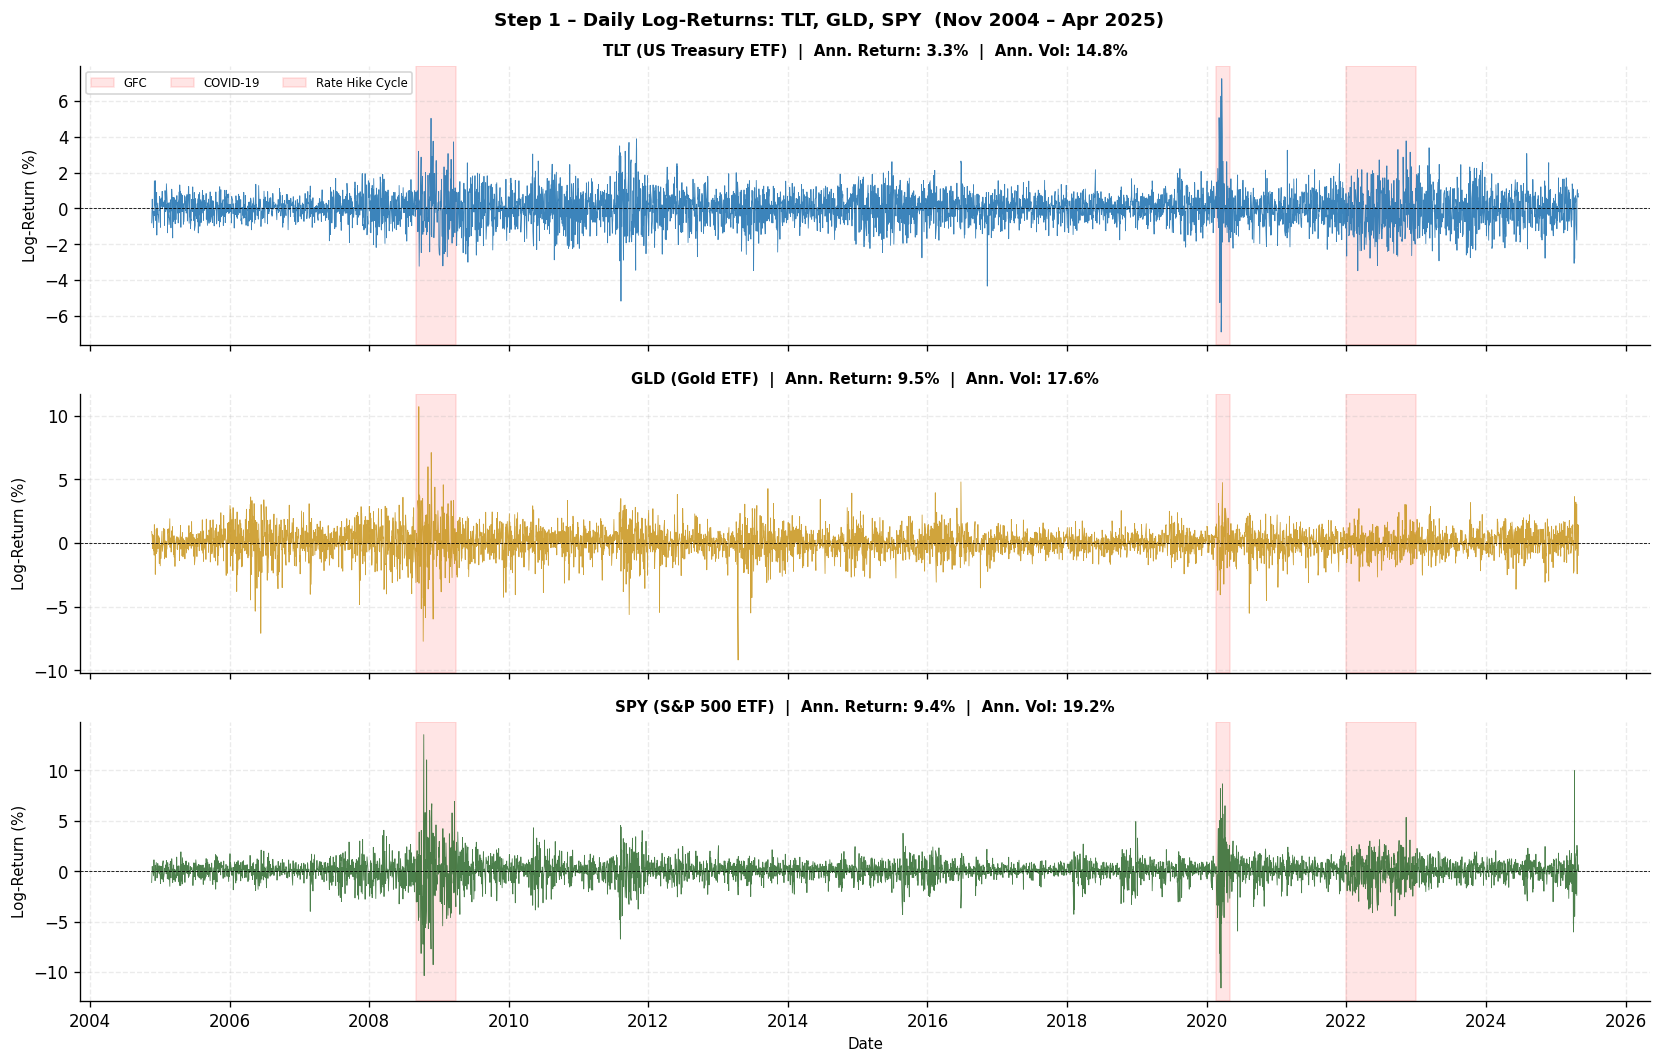

In [4]:
# ── 1.3 Plot A: ETF Log-Returns Over Time ─────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
colors = {"TLT": "#1a6faf", "GLD": "#c8941a", "SPY": "#2d6a2d"}
labels = {"TLT": "TLT (US Treasury ETF)", "GLD": "GLD (Gold ETF)", "SPY": "SPY (S&P 500 ETF)"}

# Shade major stress episodes
crises = [
    ("2008-09-01", "2009-03-31", "GFC"),
    ("2020-02-20", "2020-04-30", "COVID-19"),
    ("2022-01-01", "2022-12-31", "Rate Hike Cycle"),
]

for ax, ticker in zip(axes, ["TLT", "GLD", "SPY"]):
    ax.plot(returns.index, returns[ticker] * 100,
            color=colors[ticker], linewidth=0.5, alpha=0.85)
    ax.axhline(0, color="black", linewidth=0.5, linestyle="--")
    for s, e, lbl in crises:
        ax.axvspan(pd.Timestamp(s), pd.Timestamp(e),
                   alpha=0.10, color="red",
                   label=lbl if (ticker == "TLT") else "")
    ar = returns[ticker].mean() * 252 * 100
    av = returns[ticker].std()  * np.sqrt(252) * 100
    ax.set_ylabel("Log-Return (%)", fontsize=9)
    ax.set_title(
        f"{labels[ticker]}  |  Ann. Return: {ar:.1f}%  |  Ann. Vol: {av:.1f}%",
        fontsize=9, fontweight="bold"
    )
    if ticker == "TLT":
        ax.legend(fontsize=7, loc="upper left", ncol=3)

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].xaxis.set_major_locator(mdates.YearLocator(2))
plt.xlabel("Date", fontsize=9)
plt.suptitle("Step 1 – Daily Log-Returns: TLT, GLD, SPY  (Nov 2004 – Apr 2025)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("etf_log_returns.png", bbox_inches="tight", dpi=150)
plt.show()


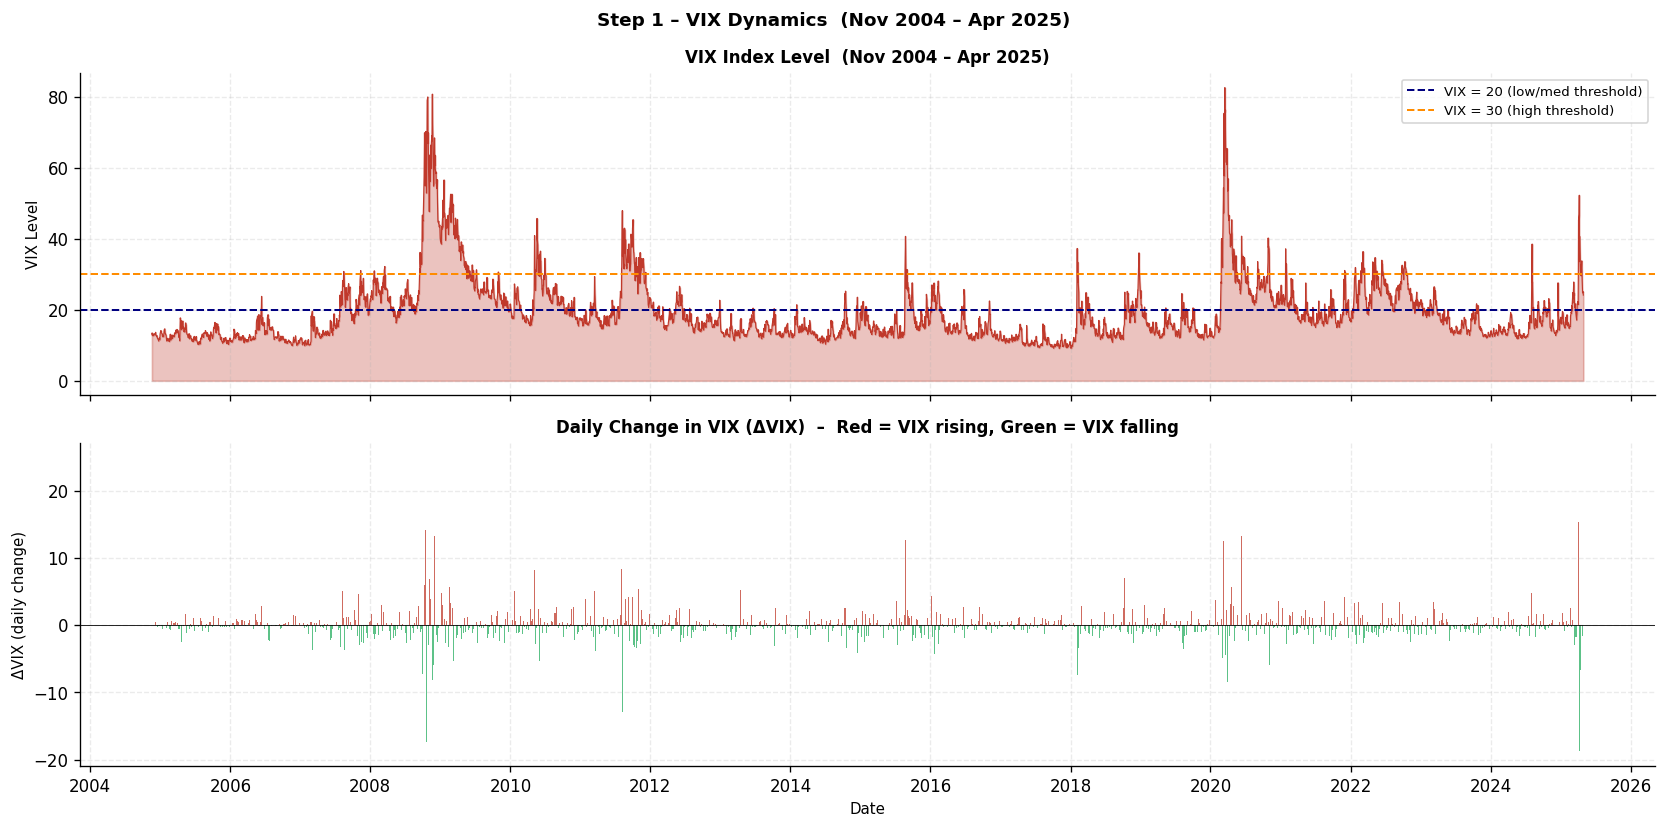

In [5]:
# ── 1.4 Plot B: VIX Level and ΔVIX ───────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# VIX level
ax1.fill_between(prices.index, prices["VIX"], alpha=0.30, color="#c0392b")
ax1.plot(prices.index, prices["VIX"], color="#c0392b", linewidth=0.7)
ax1.axhline(20, color="navy",       linewidth=1.2, linestyle="--", label="VIX = 20 (low/med threshold)")
ax1.axhline(30, color="darkorange", linewidth=1.2, linestyle="--", label="VIX = 30 (high threshold)")
ax1.set_ylabel("VIX Level", fontsize=9)
ax1.set_title("VIX Index Level  (Nov 2004 – Apr 2025)", fontsize=10, fontweight="bold")
ax1.legend(fontsize=8, loc="upper right")

# ΔVIX bar chart
bar_colors = ["#c0392b" if v > 0 else "#27ae60" for v in returns["DVIX"]]
ax2.bar(returns.index, returns["DVIX"], color=bar_colors, width=1, alpha=0.75)
ax2.axhline(0, color="black", linewidth=0.5)
ax2.set_ylabel("ΔVIX (daily change)", fontsize=9)
ax2.set_title("Daily Change in VIX (ΔVIX)  –  Red = VIX rising, Green = VIX falling",
              fontsize=10, fontweight="bold")

ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
plt.xlabel("Date", fontsize=9)
plt.suptitle("Step 1 – VIX Dynamics  (Nov 2004 – Apr 2025)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig("vix_regime_features.png", bbox_inches="tight", dpi=150)
plt.show()


# VIX Regime Modeling

This section models volatility regimes using the daily change in VIX (ΔVIX). I use Gaussian Hidden Markov Models (HMMs) with 2 and 3 states, because HMMs allow the observed VIX movement to be noisy while the underlying market volatility regime remains latent. For transparency, I also include a simple quantile-based Markov chain transition matrix as a benchmark diagnostic.

In [6]:
# ── 2.1 Helper Functions for Regime Ordering and Model Selection ──────────
from IPython.display import display

np.random.seed(42)

# HMM input: daily VIX change as a one-dimensional observation
X = returns[["DVIX"]].values
n_obs = len(X)


def count_hmm_parameters(n_states, n_features=1):
    """Approximate number of free parameters for a Gaussian HMM.
    Includes start probabilities, transition matrix, means, and diagonal/full
    one-dimensional covariance terms.
    """
    start_params = n_states - 1
    trans_params = n_states * (n_states - 1)
    mean_params = n_states * n_features
    covar_params = n_states * n_features  # one variance per state for 1D data
    return start_params + trans_params + mean_params + covar_params


def fit_hmm_model(n_states, X, random_state=42):
    model = GaussianHMM(
        n_components=n_states,
        covariance_type="full",
        n_iter=1000,
        tol=1e-6,
        random_state=random_state,
        init_params="stmc",
    )
    model.fit(X)
    log_likelihood = model.score(X)
    k = count_hmm_parameters(n_states, X.shape[1])
    aic = 2 * k - 2 * log_likelihood
    bic = np.log(len(X)) * k - 2 * log_likelihood
    hidden_states = model.predict(X)
    posterior_probs = model.predict_proba(X)
    return model, log_likelihood, aic, bic, hidden_states, posterior_probs


def order_states_by_mean_dvix(model, states, probs):
    """Relabel states from calmest to most stressed using state mean ΔVIX."""
    old_means = model.means_.flatten()
    order = np.argsort(old_means)  # lowest ΔVIX = calmest, highest = stress
    old_to_new = {old: new for new, old in enumerate(order)}
    ordered_states = np.array([old_to_new[s] for s in states])
    ordered_probs = probs[:, order]
    ordered_means = old_means[order]
    ordered_vars = np.array([model.covars_[i].reshape(-1)[0] for i in order])
    ordered_transmat = model.transmat_[order][:, order]
    return ordered_states, ordered_probs, ordered_means, ordered_vars, ordered_transmat

print(f"HMM observation count: {n_obs:,}")
print("The models will be ordered from State 0 = calm/low ΔVIX to the highest-numbered state = stress/high ΔVIX.")

HMM observation count: 5,142
The models will be ordered from State 0 = calm/low ΔVIX to the highest-numbered state = stress/high ΔVIX.


In [7]:
# ── 2.2 Fit 2-State and 3-State Gaussian HMMs ─────────────────────────────
hmm_results = {}
comparison_rows = []

for n_states in [2, 3]:
    model, ll, aic, bic, states, probs = fit_hmm_model(n_states, X)
    ordered_states, ordered_probs, ordered_means, ordered_vars, ordered_transmat = order_states_by_mean_dvix(model, states, probs)
    hmm_results[n_states] = {
        "model": model,
        "log_likelihood": ll,
        "aic": aic,
        "bic": bic,
        "states": ordered_states,
        "probs": ordered_probs,
        "means": ordered_means,
        "std": np.sqrt(ordered_vars),
        "transmat": ordered_transmat,
    }
    comparison_rows.append({
        "Model": f"{n_states}-State Gaussian HMM",
        "States": n_states,
        "Log-Likelihood": ll,
        "Parameters": count_hmm_parameters(n_states, X.shape[1]),
        "AIC": aic,
        "BIC": bic,
    })

model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
print("Model comparison: lower AIC/BIC is preferred, while higher log-likelihood indicates better in-sample fit.")
display(model_comparison.round(2))

for n_states, res in hmm_results.items():
    print(f"\n{n_states}-State HMM fitted state parameters ordered by mean ΔVIX:")
    params = pd.DataFrame({
        "State": [f"State {i}" for i in range(n_states)],
        "Mean ΔVIX": res["means"],
        "Std. Dev. ΔVIX": res["std"],
    }).set_index("State")
    display(params.round(4))
    print("Transition matrix:")
    trans = pd.DataFrame(
        res["transmat"],
        index=[f"From State {i}" for i in range(n_states)],
        columns=[f"To State {i}" for i in range(n_states)],
    )
    display(trans.round(4))

Model comparison: lower AIC/BIC is preferred, while higher log-likelihood indicates better in-sample fit.


,States,Log-Likelihood,Parameters,AIC,BIC
Model,,,,,
2-State Gaussian HMM,2,-8760.73,7,17535.46,17581.27
3-State Gaussian HMM,3,-8417.73,14,16863.46,16955.09



2-State HMM fitted state parameters ordered by mean ΔVIX:


,Mean ΔVIX,Std. Dev. ΔVIX
State,,
State 0,-0.0733,0.8182
State 1,0.2237,3.5412


Transition matrix:


,To State 0,To State 1
From State 0,0.9614,0.0386
From State 1,0.1131,0.8869



3-State HMM fitted state parameters ordered by mean ΔVIX:


,Mean ΔVIX,Std. Dev. ΔVIX
State,,
State 0,-0.0606,0.6063
State 1,-0.0153,1.7047
State 2,0.6161,5.9170


Transition matrix:


,To State 0,To State 1,To State 2
From State 0,0.9408,0.0584,0.0008
From State 1,0.0687,0.9138,0.0175
From State 2,0.0000,0.1244,0.8756


In [8]:
# ── 2.3 Optional Diagnostic: Quantile Markov Chain on ΔVIX ────────────────
# This is included as a transparent benchmark, while the HMM remains the main model.
mc_states = pd.qcut(returns["DVIX"], q=3, labels=["Low ΔVIX", "Medium ΔVIX", "High ΔVIX"])
mc_df = pd.DataFrame({"state": mc_states}).dropna()
transition_counts = pd.crosstab(mc_df["state"].shift(1), mc_df["state"], normalize="index")
stationary_counts = mc_df["state"].value_counts(normalize=True).sort_index()

print("Quantile-based Markov chain transition matrix for ΔVIX:")
display(transition_counts.round(4))
print("Empirical stationary distribution / unconditional state frequencies:")
display(stationary_counts.rename("Probability").to_frame().round(4))

Quantile-based Markov chain transition matrix for ΔVIX:


state,Low ΔVIX,Medium ΔVIX,High ΔVIX
state,,,
Low ΔVIX,0.3508,0.3055,0.3438
Medium ΔVIX,0.2370,0.4339,0.3291
High ΔVIX,0.4183,0.2620,0.3196


Empirical stationary distribution / unconditional state frequencies:


,Probability
state,
Low ΔVIX,0.3351
Medium ΔVIX,0.3339
High ΔVIX,0.3310


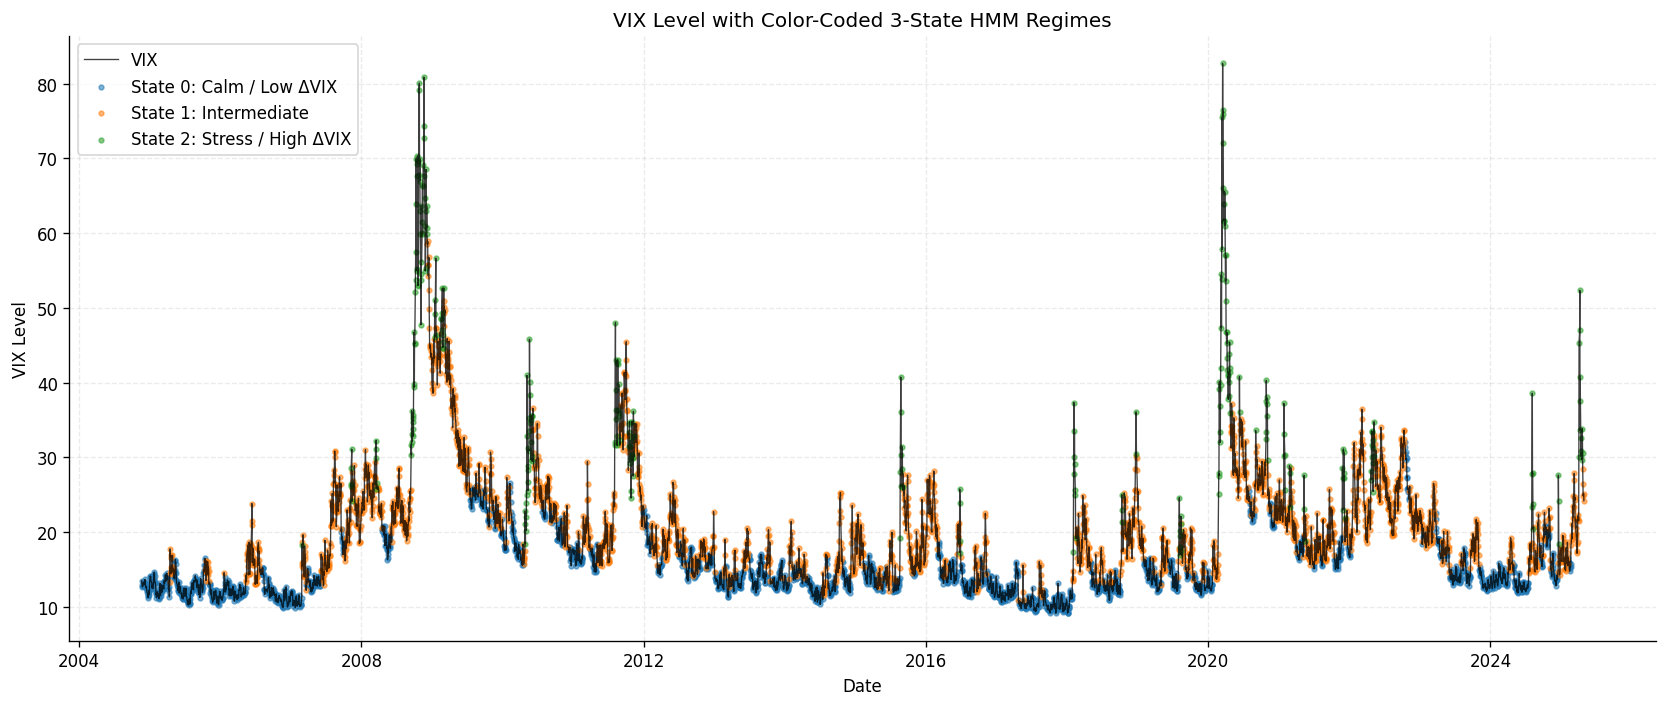

Selected by BIC: 3-State Gaussian HMM


In [9]:
# ── 2.4 Plot VIX with Color-Coded HMM States ──────────────────────────────
# Use the BIC-preferred HMM unless AIC and BIC disagree strongly.
best_states_n = int(model_comparison["BIC"].idxmin().split("-")[0])
best = hmm_results[best_states_n]
returns = returns.copy()
returns[f"HMM_{best_states_n}_State"] = best["states"]
for i in range(best_states_n):
    returns[f"Prob_State_{i}"] = best["probs"][:, i]

regime_labels = {0: "Calm / Low ΔVIX", 1: "Intermediate", 2: "Stress / High ΔVIX"}
if best_states_n == 2:
    regime_labels = {0: "Calm / Low ΔVIX", 1: "Stress / High ΔVIX"}

plot_data = prices.loc[returns.index, ["VIX"]].join(returns[[f"HMM_{best_states_n}_State"]])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(plot_data.index, plot_data["VIX"], color="black", linewidth=0.8, alpha=0.75, label="VIX")

for state in range(best_states_n):
    state_dates = plot_data.index[plot_data[f"HMM_{best_states_n}_State"] == state]
    ax.scatter(
        state_dates,
        plot_data.loc[state_dates, "VIX"],
        s=8,
        alpha=0.55,
        label=f"State {state}: {regime_labels.get(state, 'State ' + str(state))}",
    )

ax.set_title(f"VIX Level with Color-Coded {best_states_n}-State HMM Regimes")
ax.set_xlabel("Date")
ax.set_ylabel("VIX Level")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Selected by BIC: {best_states_n}-State Gaussian HMM")

# Regime State Selection and Interpretation

The preferred model is selected using information criteria and interpretability. Log-likelihood usually improves when the number of states increases, but AIC and BIC penalize unnecessary parameters. BIC is emphasized because it applies a stronger penalty for model complexity, which helps avoid overfitting in a strategy that will later be backtested.

In [10]:
# ── 3.1 Select Preferred Model and Summarize State Frequencies ────────────
selected_n = best_states_n
selected_state_col = f"HMM_{selected_n}_State"

state_frequency = returns[selected_state_col].value_counts(normalize=True).sort_index()
state_summary = pd.DataFrame({
    "Regime Label": [regime_labels.get(i, f"State {i}") for i in range(selected_n)],
    "Frequency (%)": 100 * state_frequency.reindex(range(selected_n)).fillna(0),
    "Mean ΔVIX": best["means"],
    "Std. Dev. ΔVIX": best["std"],
})
state_summary.index = [f"State {i}" for i in range(selected_n)]

print("Preferred model and regime summary:")
display(state_summary.round(3))

print(
    f"The selected specification is the {selected_n}-state HMM because it has the lowest BIC in the candidate set. "
    "The ordered state means show an intuitive progression from calmer periods to higher VIX shock periods."
)

Preferred model and regime summary:


,Regime Label,Frequency (%),Mean ΔVIX,Std. Dev. ΔVIX
State 0,Calm / Low ΔVIX,50.467,-0.061,0.606
State 1,Intermediate,43.816,-0.015,1.705
State 2,Stress / High ΔVIX,5.718,0.616,5.917


The selected specification is the 3-state HMM because it has the lowest BIC in the candidate set. The ordered state means show an intuitive progression from calmer periods to higher VIX shock periods.


State-conditional ETF return behavior:


Annualized Mean Return (%)                Annualized Volatility (%)  \
                               TLT    GLD     SPY                       TLT   
State 0                      -3.59  11.27   32.78                     11.85   
State 1                       6.09   7.05   -0.61                     15.40   
State 2                      42.17  11.98 -119.67                     27.50   

                       
           GLD    SPY  
State 0  14.73   8.70  
State 1  17.98  19.23  
State 2  31.79  53.67

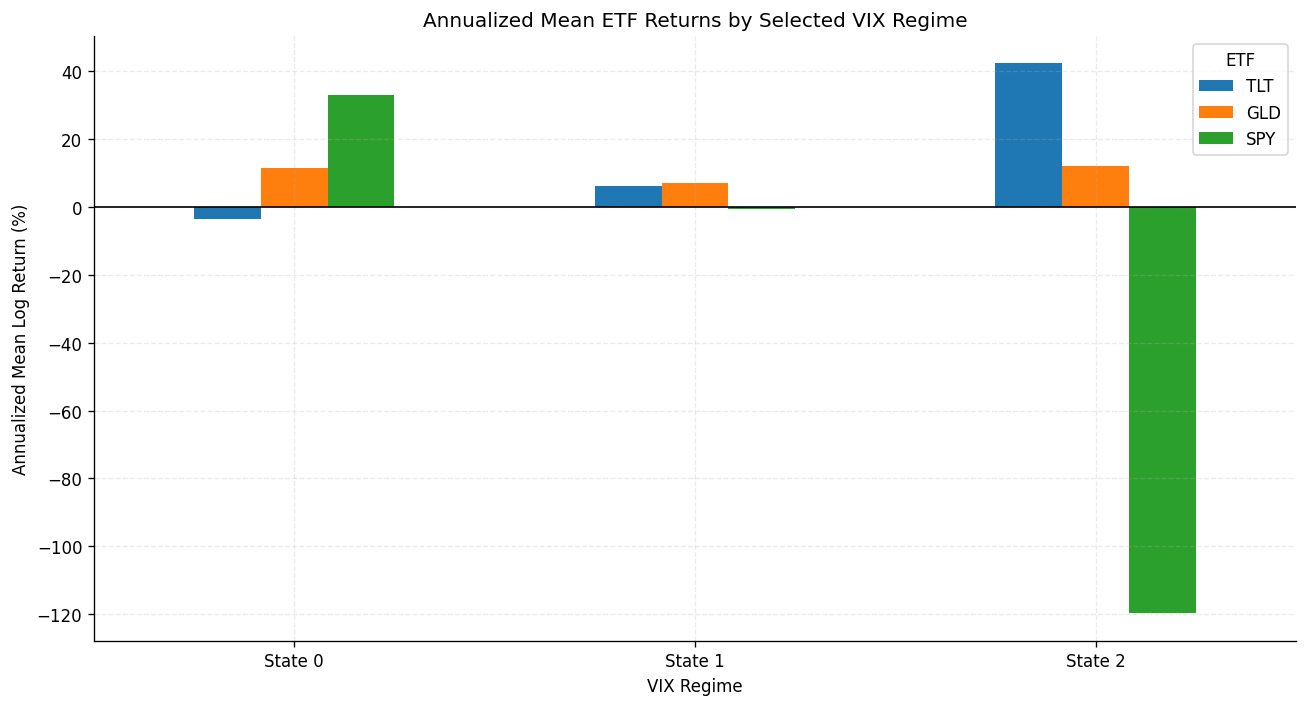

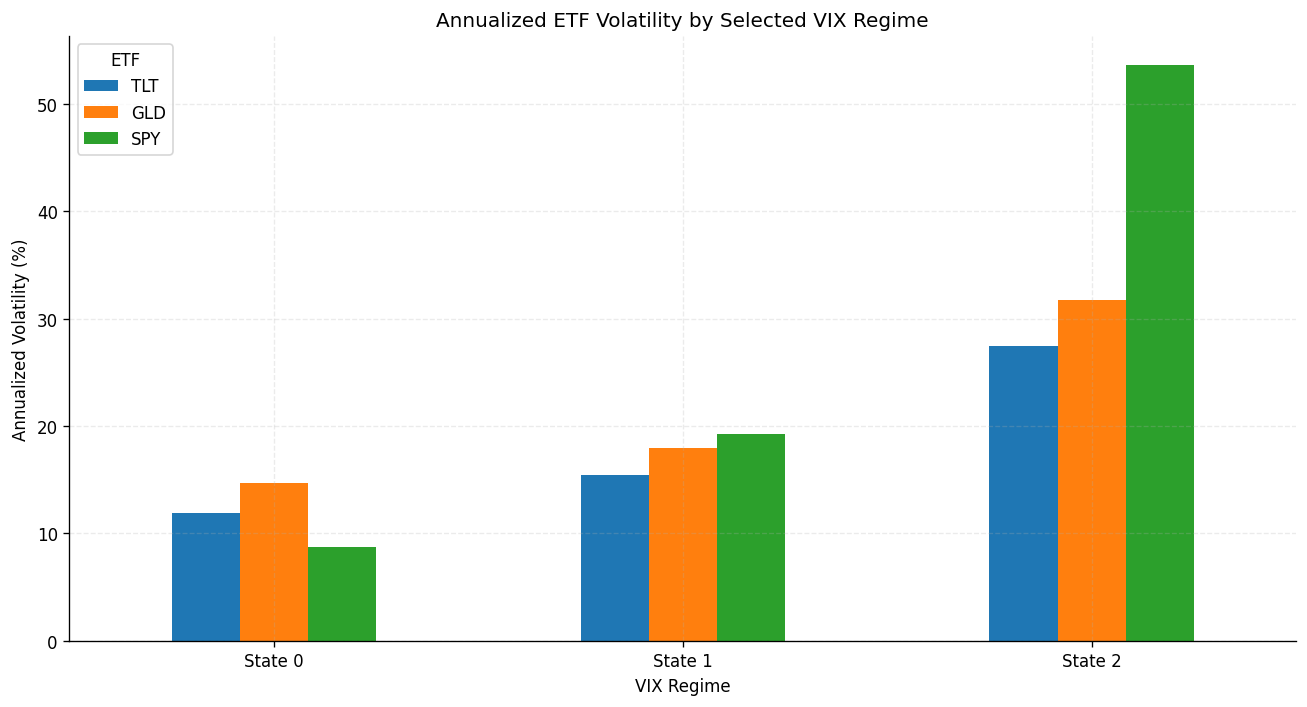

In [11]:
# ── 3.2 ETF Return Mean and Volatility by Selected State ──────────────────
etf_cols = ["TLT", "GLD", "SPY"]
state_return_mean = returns.groupby(selected_state_col)[etf_cols].mean() * 252 * 100
state_return_std = returns.groupby(selected_state_col)[etf_cols].std() * np.sqrt(252) * 100

state_conditional_table = pd.concat(
    {"Annualized Mean Return (%)": state_return_mean, "Annualized Volatility (%)": state_return_std},
    axis=1,
)
state_conditional_table.index = [f"State {i}" for i in state_conditional_table.index]

print("State-conditional ETF return behavior:")
display(state_conditional_table.round(2))

# Bar chart of annualized mean returns by state
ax = state_return_mean.rename(index=lambda x: f"State {x}").plot(kind="bar", figsize=(11, 6))
ax.set_title("Annualized Mean ETF Returns by Selected VIX Regime")
ax.set_xlabel("VIX Regime")
ax.set_ylabel("Annualized Mean Log Return (%)")
ax.axhline(0, linewidth=1, color="black")
ax.legend(title="ETF")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Bar chart of annualized volatility by state
ax = state_return_std.rename(index=lambda x: f"State {x}").plot(kind="bar", figsize=(11, 6))
ax.set_title("Annualized ETF Volatility by Selected VIX Regime")
ax.set_xlabel("VIX Regime")
ax.set_ylabel("Annualized Volatility (%)")
ax.legend(title="ETF")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Regime-Based ETF Rotation Strategy

The strategy uses a simple regime-to-asset rule. For each selected VIX state, the ETF with the highest historical annualized mean return in that state receives a 100% allocation. A one-day execution lag is then applied in the backtest so that today's allocation uses yesterday's inferred regime instead of today's realized return information.

In [12]:
# ── 4.1 Create State → ETF Allocation Rule ────────────────────────────────
allocation_asset = state_return_mean.idxmax(axis=1).to_dict()
allocation_table = pd.DataFrame({
    "Regime": [regime_labels.get(i, f"State {i}") for i in range(selected_n)],
    "Selected ETF": [allocation_asset[i] for i in range(selected_n)],
    "Reason": [
        f"Highest in-sample annualized mean return in State {i}: {state_return_mean.loc[i, allocation_asset[i]]:.2f}%"
        for i in range(selected_n)
    ],
}, index=[f"State {i}" for i in range(selected_n)])

print("Final regime-to-allocation mapping:")
display(allocation_table)

print(
    "Decision rule: identify the current VIX regime, wait one trading day, and allocate 100% "
    "to the ETF that historically performed best in that regime. The lag is included to reduce lookahead bias."
)

Final regime-to-allocation mapping:


,Regime,Selected ETF,Reason
State 0,Calm / Low ΔVIX,SPY,Highest in-sample annualized mean return in St...
State 1,Intermediate,GLD,Highest in-sample annualized mean return in St...
State 2,Stress / High ΔVIX,TLT,Highest in-sample annualized mean return in St...


Decision rule: identify the current VIX regime, wait one trading day, and allocate 100% to the ETF that historically performed best in that regime. The lag is included to reduce lookahead bias.


# Strategy Backtesting and Evaluation

This section compares the regime rotation strategy with two benchmarks: an equal-weight TLT/GLD/SPY portfolio and buy-and-hold SPY. The strategy applies a one-day execution lag, and all performance metrics are computed from daily simple returns.

In [13]:
# ── 5.1 Build Strategy and Benchmark Returns ──────────────────────────────
simple_returns = np.exp(returns[etf_cols]) - 1

# Lag the state by one day to avoid using same-day information.
lagged_state = returns[selected_state_col].shift(1)
strategy_ret = pd.Series(index=returns.index, dtype=float, name="Regime Rotation")
selected_asset_series = pd.Series(index=returns.index, dtype=object, name="Selected Asset")

for dt in returns.index:
    state = lagged_state.loc[dt]
    if pd.isna(state):
        strategy_ret.loc[dt] = 0.0
        selected_asset_series.loc[dt] = "Cash/No Position"
    else:
        state = int(state)
        asset = allocation_asset[state]
        selected_asset_series.loc[dt] = asset
        strategy_ret.loc[dt] = simple_returns.loc[dt, asset]

# Equal-weight benchmark. For a daily-return approximation, 1/3 is applied to each ETF.
# This is equivalent to a frequently rebalanced equal-weight reference and is a clean baseline.
equal_weight_ret = simple_returns[etf_cols].mean(axis=1).rename("Equal Weight 1/3")
spy_ret = simple_returns["SPY"].rename("Buy-and-Hold SPY")

portfolio_returns = pd.concat([strategy_ret, equal_weight_ret, spy_ret], axis=1).dropna()
cumulative_returns = (1 + portfolio_returns).cumprod()

print("Backtest return series prepared:")
display(portfolio_returns.head().round(5))
print("Final selected asset counts after one-day state lag:")
display(selected_asset_series.value_counts().to_frame("Days"))

Backtest return series prepared:


,Regime Rotation,Equal Weight 1/3,Buy-and-Hold SPY
Date,,,
2004-11-19,0.00000,-0.00336,-0.01112
2004-11-22,0.00477,0.00459,0.00477
2004-11-23,0.00153,-0.00056,0.00153
2004-11-24,0.00237,0.00302,0.00237
2004-11-26,-0.00076,-0.00065,-0.00076


Final selected asset counts after one-day state lag:


,Days
Selected Asset,
SPY,2595
GLD,2252
TLT,294
Cash/No Position,1


In [14]:
# ── 5.2 Performance Metrics ───────────────────────────────────────────────
def max_drawdown(return_series):
    cumulative = (1 + return_series).cumprod()
    running_max = cumulative.cummax()
    drawdown = cumulative / running_max - 1
    return drawdown.min()


def performance_metrics(return_df, periods_per_year=252):
    rows = []
    for col in return_df.columns:
        r = return_df[col].dropna()
        total_return = (1 + r).prod() - 1
        years = len(r) / periods_per_year
        ann_return = (1 + total_return) ** (1 / years) - 1
        ann_vol = r.std() * np.sqrt(periods_per_year)
        sharpe = ann_return / ann_vol if ann_vol != 0 else np.nan
        mdd = max_drawdown(r)
        rows.append({
            "Portfolio": col,
            "Cumulative Return (%)": total_return * 100,
            "Annualized Return (%)": ann_return * 100,
            "Annualized Volatility (%)": ann_vol * 100,
            "Sharpe Ratio (rf=0)": sharpe,
            "Max Drawdown (%)": mdd * 100,
        })
    return pd.DataFrame(rows).set_index("Portfolio")

metrics_table = performance_metrics(portfolio_returns)
print("Performance comparison:")
display(metrics_table.round(2))

Performance comparison:


,Cumulative Return (%),Annualized Return (%),Annualized Volatility (%),Sharpe Ratio (rf=0),Max Drawdown (%)
Portfolio,,,,,
Regime Rotation,2164.02,16.52,14.83,1.11,-26.23
Equal Weight 1/3,456.45,8.78,9.68,0.91,-22.74
Buy-and-Hold SPY,585.47,9.89,19.20,0.52,-55.19


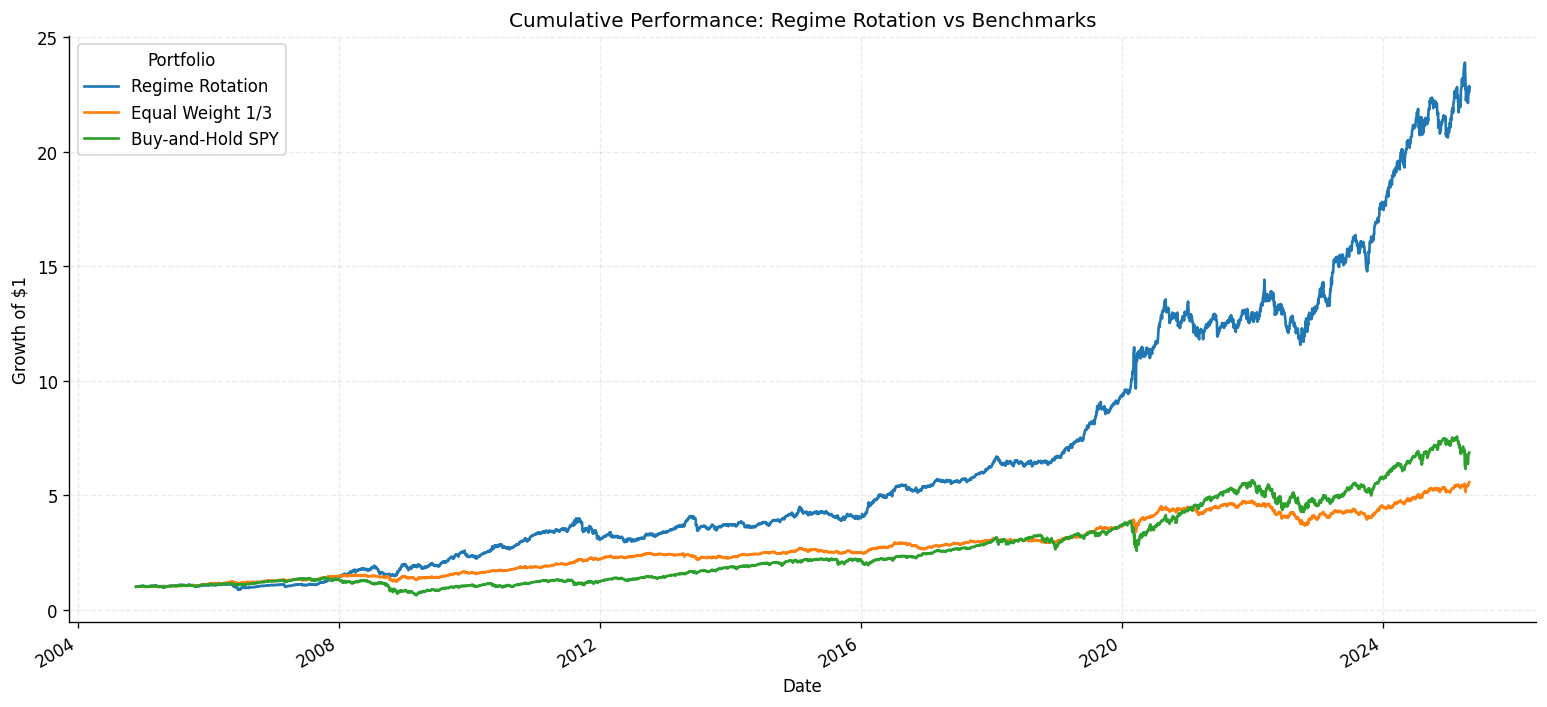

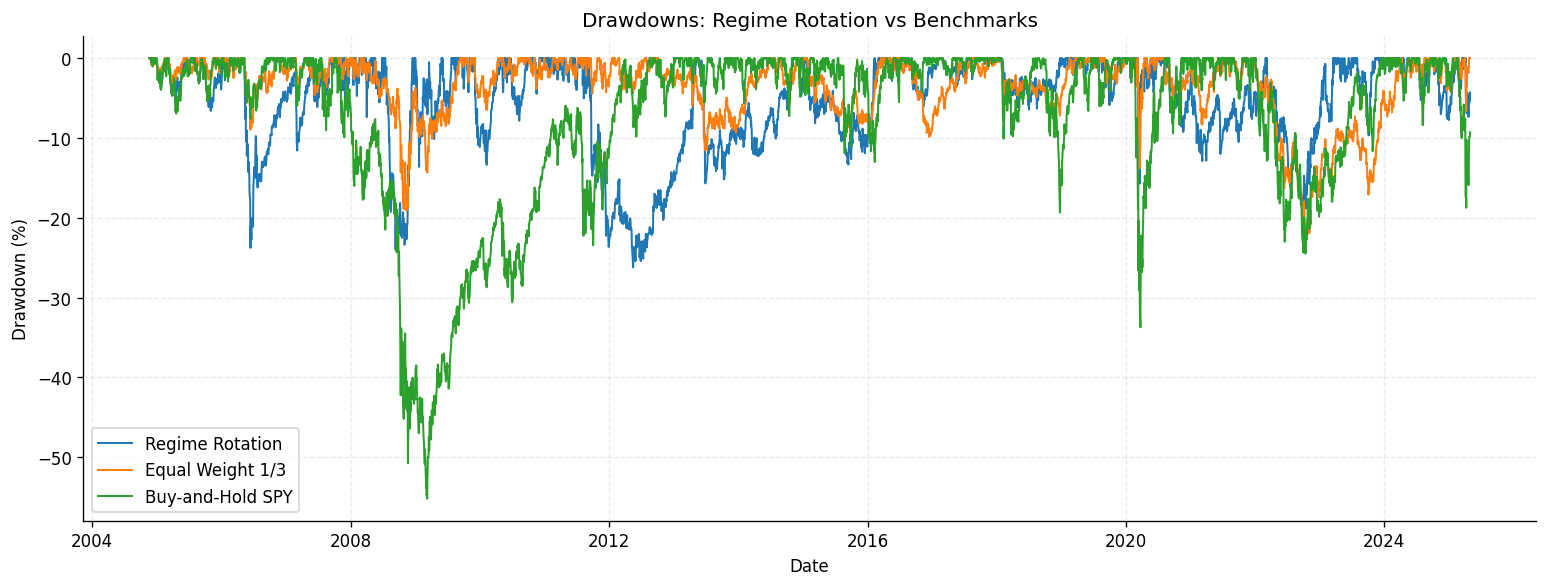

In [15]:
# ── 5.3 Plot Cumulative Performance Curves ────────────────────────────────
ax = cumulative_returns.plot(figsize=(13, 6), linewidth=1.6)
ax.set_title("Cumulative Performance: Regime Rotation vs Benchmarks")
ax.set_xlabel("Date")
ax.set_ylabel("Growth of $1")
ax.legend(title="Portfolio")
plt.tight_layout()
plt.show()

# Drawdown plot
fig, ax = plt.subplots(figsize=(13, 5))
for col in portfolio_returns.columns:
    cum = (1 + portfolio_returns[col]).cumprod()
    dd = cum / cum.cummax() - 1
    ax.plot(dd.index, dd * 100, linewidth=1.2, label=col)
ax.set_title("Drawdowns: Regime Rotation vs Benchmarks")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
# ── 5.4 Sensitivity Check: 2-State vs 3-State HMM Rotation ────────────────
sensitivity_rows = []

for n in [2, 3]:
    temp_returns = returns.copy()
    temp_returns[f"HMM_{n}_State"] = hmm_results[n]["states"]
    temp_mean = temp_returns.groupby(f"HMM_{n}_State")[etf_cols].mean() * 252 * 100
    temp_alloc = temp_mean.idxmax(axis=1).to_dict()
    temp_lagged = temp_returns[f"HMM_{n}_State"].shift(1)
    temp_strategy = pd.Series(index=temp_returns.index, dtype=float)
    for dt in temp_returns.index:
        st = temp_lagged.loc[dt]
        if pd.isna(st):
            temp_strategy.loc[dt] = 0.0
        else:
            temp_strategy.loc[dt] = simple_returns.loc[dt, temp_alloc[int(st)]]
    temp_metrics = performance_metrics(pd.DataFrame({f"{n}-State Strategy": temp_strategy}))
    sensitivity_rows.append(temp_metrics.iloc[0])

sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table.index = ["2-State Strategy", "3-State Strategy"]
print("Sensitivity to number of HMM states:")
display(sensitivity_table.round(2))

print(
    "Interpretation: if the selected model has materially higher Sharpe ratio and/or lower drawdown than the alternative, "
    "the chosen number of states is more useful for allocation. If results are close, the simpler 2-state model may be preferred for stability."
)

Sensitivity to number of HMM states:


,Cumulative Return (%),Annualized Return (%),Annualized Volatility (%),Sharpe Ratio (rf=0),Max Drawdown (%)
2-State Strategy,3397.74,19.03,14.39,1.32,-19.54
3-State Strategy,2164.02,16.52,14.83,1.11,-26.23


Interpretation: if the selected model has materially higher Sharpe ratio and/or lower drawdown than the alternative, the chosen number of states is more useful for allocation. If results are close, the simpler 2-state model may be preferred for stability.


# Final Notebook Interpretation

The completed workflow starts with cleaned common-sample ETF and VIX data, identifies volatility regimes from ΔVIX, selects the preferred candidate using AIC/BIC, translates the selected state sequence into a transparent allocation rule, and evaluates the resulting rotation strategy against equal-weight and SPY benchmarks. The one-day lag in the backtest is important because it prevents the allocation from using information that would only be known after the trading day is complete.